In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate customer IDs:",
      df["customerID"].duplicated().sum())

print("\nChurn categories:")
print(df["Churn"].value_counts())

Missing values:


,Missing Count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate customer IDs: 0

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [17]:
df = df.drop_duplicates(subset="customerID").copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("\nCleaned dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
display(df.head())

Missing TotalCharges: 11

Cleaned dataset shape: (7043, 21)
Remaining missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Business Question 1 — What is the overall churn rate?
This is our baseline metric. It tells us what percentage of the company's customers have left.

The formula is:
**Churn Rate = Customers who left / Total customers * 100**

CUSTOMER CHURN BASELINE
-----------------------------------
Total customers: 7043
Churned customers: 1869
Retained customers: 5174
Churn rate: 26.54%
Retention rate: 73.46%


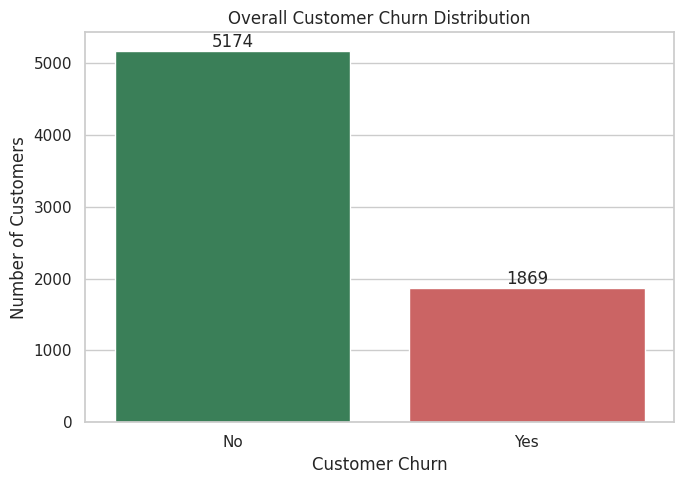

In [18]:
churn_counts = df["Churn"].value_counts()
total_customers = len(df)
churned_customers = churn_counts.get("Yes", 0)
retained_customers = churn_counts.get("No", 0)
churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100
print("CUSTOMER CHURN BASELINE")
print("-" * 35)
print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customers)
print(f"Churn rate: {churn_rate:.2f}%")
print(f"Retention rate: {retention_rate:.2f}%")
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df,x="Churn",hue="Churn",order=["No", "Yes"],palette=["#2E8B57", "#DC5353"],legend=False)
plt.title("Overall Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("01_overall_churn.png", dpi=300, bbox_inches="tight")
plt.show()

Business Question 2 — How do contract durations influence churn?
We will compare three contract categories:

- Month-to-month
- One year
- Two years
The important metric is the churn rate within each contract group, not simply the number of churned customers. This makes the comparison fair even when group sizes differ.

,total_customers,churned_customers,churn_rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


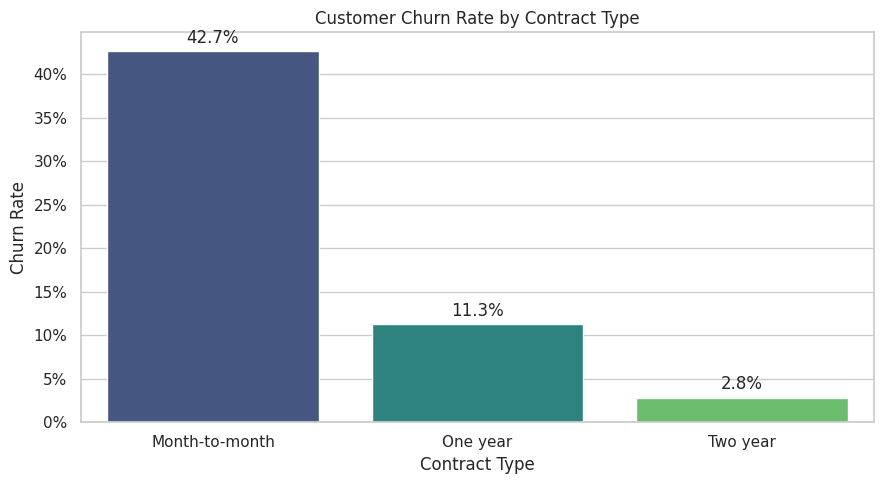

In [19]:
contract_churn = (df.groupby("Contract", observed=True).agg(total_customers=("customerID", "count"),churned_customers=("Churn",lambda x: (x == "Yes").sum())))

contract_churn["churn_rate"] = (contract_churn["churned_customers"] /contract_churn["total_customers"] * 100)
contract_churn = contract_churn.sort_values("churn_rate", ascending=False)
display(contract_churn.round(2))

plt.figure(figsize=(9, 5))

ax = sns.barplot(data=df,x="Contract",y=df["Churn"].eq("Yes").astype(int),order=["Month-to-month", "One year", "Two year"],hue="Contract",palette="viridis",estimator="mean",errorbar=None,legend=False)
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}%"))
for container in ax.containers:
    ax.bar_label(container,labels=[f"{bar.get_height()*100:.1f}%"for bar in container],padding=3)
plt.tight_layout()
plt.savefig("02_contract_churn.png", dpi=300, bbox_inches="tight")
plt.show()

Business Question 3 — Does payment method correlate with churn?
We'll compare four payment methods:

1. Electronic check
2. Mailed check
3. Bank transfer (automatic)
4. Credit card (automatic)

,total_customers,churned_customers,churn_rate
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


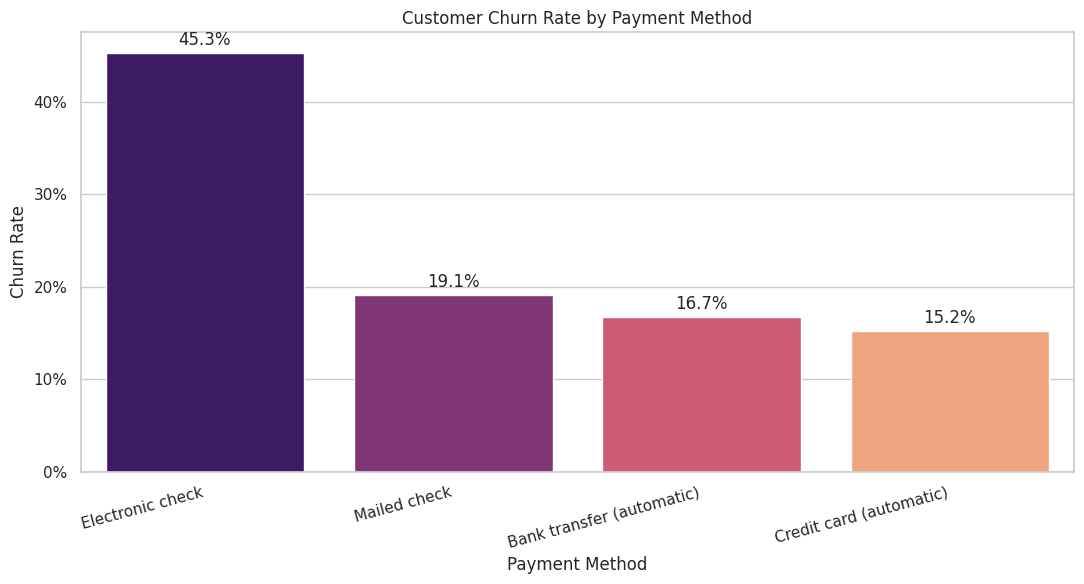

In [20]:
payment_churn = (df.groupby("PaymentMethod", observed=True).agg(total_customers=("customerID", "count"),churned_customers=("Churn",lambda x: (x == "Yes").sum())))
payment_churn["churn_rate"] = (payment_churn["churned_customers"] /payment_churn["total_customers"] * 100)
payment_churn = payment_churn.sort_values("churn_rate", ascending=False)
display(payment_churn.round(2))

plt.figure(figsize=(11, 6))

ax = sns.barplot(data=df,x="PaymentMethod",y=df["Churn"].eq("Yes").astype(int),hue="PaymentMethod",estimator="mean",errorbar=None,palette="magma",legend=False)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate")
plt.xticks(rotation=15, ha="right")

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}%"))
for container in ax.containers:
    ax.bar_label(container,labels=[f"{bar.get_height()*100:.1f}%"for bar in container],padding=3)
plt.tight_layout()
plt.savefig("03_payment_churn.png", dpi=300, bbox_inches="tight")
plt.show()

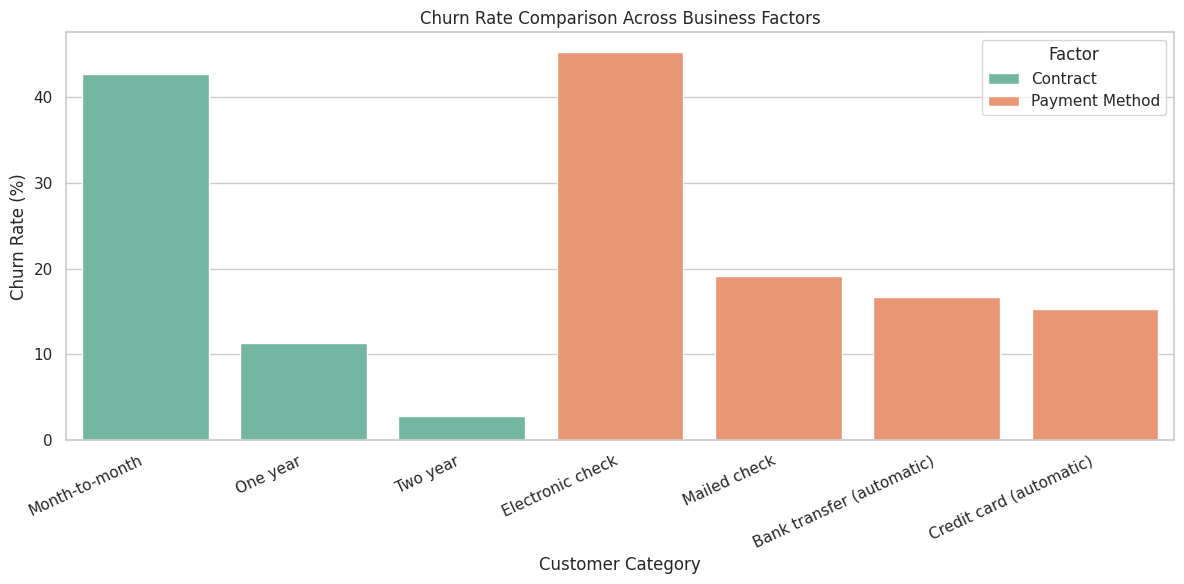

In [21]:
summary_data = pd.concat([contract_churn["churn_rate"].rename_axis("Category").reset_index().assign(Factor="Contract"),
    payment_churn["churn_rate"].rename_axis("Category").reset_index().assign(Factor="Payment Method")], ignore_index=True)
plt.figure(figsize=(12, 6))
sns.barplot(data=summary_data,x="Category",y="churn_rate",hue="Factor",palette="Set2")
plt.title("Churn Rate Comparison Across Business Factors")
plt.xlabel("Customer Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("04_churn_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
highest_contract = contract_churn["churn_rate"].idxmax()
lowest_contract = contract_churn["churn_rate"].idxmin()

highest_payment = payment_churn["churn_rate"].idxmax()
lowest_payment = payment_churn["churn_rate"].idxmin()

print("=" * 55)
print("CUSTOMER CHURN STORYBOARD — BUSINESS FINDINGS")
print("=" * 55)

print(f"\n1. Overall churn rate: {churn_rate:.2f}%")

print(f"\n2. Highest churn contract: {highest_contract} "f"({contract_churn.loc[highest_contract, 'churn_rate']:.2f}%)")
print(f"   Lowest churn contract: {lowest_contract} "f"({contract_churn.loc[lowest_contract, 'churn_rate']:.2f}%)")
print(f"\n3. Highest churn payment method: {highest_payment} "f"({payment_churn.loc[highest_payment, 'churn_rate']:.2f}%)")
print(f"   Lowest churn payment method: {lowest_payment} "f"({payment_churn.loc[lowest_payment, 'churn_rate']:.2f}%)")

CUSTOMER CHURN STORYBOARD — BUSINESS FINDINGS

1. Overall churn rate: 26.54%

2. Highest churn contract: Month-to-month (42.71%)
   Lowest churn contract: Two year (2.83%)

3. Highest churn payment method: Electronic check (45.29%)
   Lowest churn payment method: Credit card (automatic) (15.24%)
